# 04 - Explainability (SHAP & LIME)

**Goal:** explain *why* the model predicts purchase, globally and for individual sessions.

- **SHAP** = additive contribution of each feature to a prediction (global view by averaging).
- **LIME** = a small interpretable model fitted around one prediction (second opinion).

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import logging; logging.disable(logging.INFO)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.config.settings import get_settings
from src.data.loader import load_dataset
S = get_settings()
df = load_dataset(S)
sns.set_theme(style="whitegrid")
from src.models.predictor import Predictor
pred = Predictor()
X = df[S.input_columns]
sample = X.sample(1000, random_state=42)

## 1. Global importance

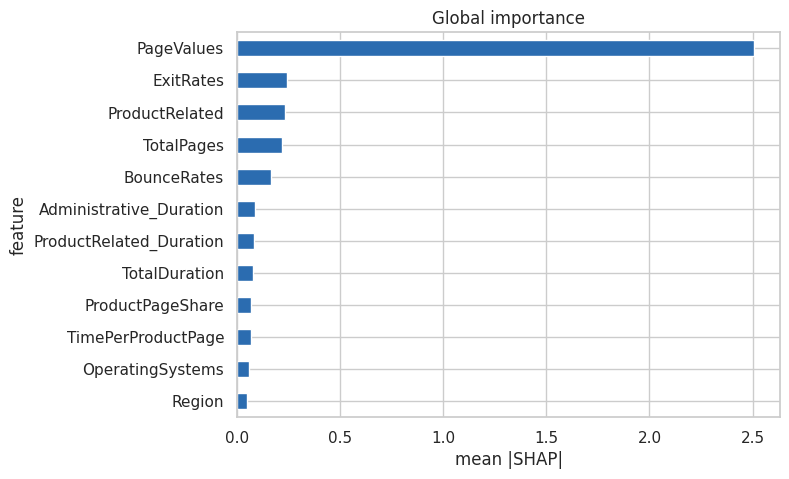

,feature,mean_abs_shap
0,PageValues,2.507465
1,ExitRates,0.243165
2,ProductRelated,0.228924
3,TotalPages,0.214575
4,BounceRates,0.163194
5,Administrative_Duration,0.084505
6,ProductRelated_Duration,0.082800
7,TotalDuration,0.077075


In [2]:
imp = pred.explainer.global_importance(sample)
imp.head(12).iloc[::-1].plot.barh(x='feature', y='mean_abs_shap', legend=False, figsize=(7, 5), color='#2b6cb0'); plt.xlabel('mean |SHAP|'); plt.title('Global importance'); plt.show()
imp.head(8)

**Reading:** `PageValues` is by far the dominant driver, followed by `ExitRates`, product-page engagement (`ProductRelated`, `TotalPages`) and `BounceRates`. Calendar/ID features contribute little. This matches the EDA and the ablation.

## 2. Direction of effects (beeswarm)

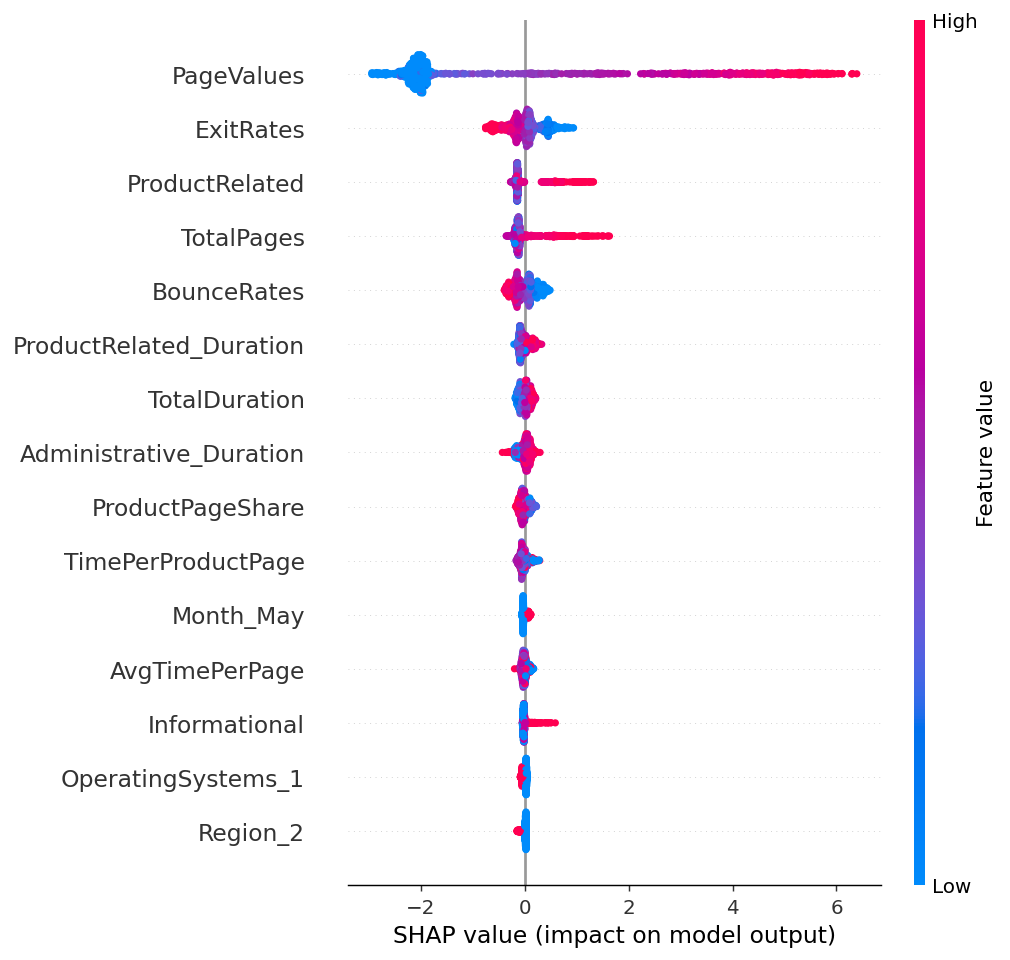

In [3]:
from IPython.display import Image
Image(str(S.path('figures_dir') / 'shap_beeswarm.png'))

**Reading:** high `PageValues` pushes strongly towards purchase; high `ExitRates` and `BounceRates` push away from it; more product-page views push towards it.

## 3. Local explanation of three sessions
A confident buyer, a confident non-buyer and a borderline case.

In [4]:
import json
ex = json.load(open(S.path('reports_dir') / 'local_examples.json'))
for tag, e in ex.items():
    print(f"\n=== {tag.replace('_',' ').upper()} | P(buy)={e['probability']:.1%} | actual={'bought' if e['actual'] else 'no purchase'}")
    print(pd.DataFrame(e['shap_top'])[['feature','value','shap_value']].to_string(index=False))


=== LIKELY BUYER | P(buy)=99.5% | actual=bought
       feature    value  shap_value
    PageValues  55.2981      4.9430
    TotalPages 101.0000      1.6225
ProductRelated  95.0000      1.2574
     ExitRates   0.0000      0.9281
   BounceRates   0.0000      0.3577

=== LIKELY NON BUYER | P(buy)=0.0% | actual=no purchase
                feature   value  shap_value
             PageValues  0.0000     -1.9150
              ExitRates  0.0961     -0.6922
            BounceRates  0.0476     -0.3254
Administrative_Duration  0.0000     -0.1670
     TimePerProductPage 33.1423     -0.1504

=== BORDERLINE | P(buy)=14.0% | actual=no purchase
                feature     value  shap_value
             PageValues   10.7495      2.3588
            BounceRates    0.0029      0.1945
          TotalDuration 1238.1399      0.1538
ProductRelated_Duration 1191.8355      0.1530
             TotalPages   29.0000     -0.1019


## 4. LIME as a second opinion

In [5]:
for tag, e in ex.items():
    print(f"\n--- {tag} (LIME top rules)")
    print(pd.DataFrame(e['lime_top']).head(5).to_string(index=False))


--- likely_buyer (LIME top rules)
                                rule  weight
             skew__PageValues > 0.99  0.4844
      cat__VisitorType_Other <= 0.00  0.0532
              cat__Browser_7 <= 0.00  0.0458
skew__ProductRelated_Duration > 0.50  0.0370
           cat__TrafficType_3 > 0.00  0.0336

--- likely_non_buyer (LIME top rules)
                          rule  weight
      skew__PageValues <= 0.00 -0.2998
       cat__Browser_13 <= 0.00 -0.0894
    cat__TrafficType_9 <= 0.00 -0.0638
cat__VisitorType_Other <= 0.00 -0.0582
        cat__Month_Feb <= 0.00 -0.0543

--- borderline (LIME top rules)
                           rule  weight
        cat__Browser_13 <= 0.00  0.1258
        cat__Browser_12 <= 0.00 -0.1166
0.00 < skew__PageValues <= 0.99 -0.1144
         cat__Browser_7 <= 0.00 -0.1098
          cat__Month_Aug > 0.00  0.0632


**Reading:** LIME and SHAP agree on the dominant driver, `PageValues`, in all three examples. Beyond that they diverge: LIME works on the *encoded* columns, so its secondary rules are often one-hot flags (e.g. a specific `Browser_*` or `TrafficType_*` being 0) that carry little real signal. Treat LIME as a coarse second opinion and trust SHAP (exact for tree models) for secondary drivers.

## 5. What-if analysis (sensitivity to PageValues)
Hold one borderline session fixed and vary a single feature.

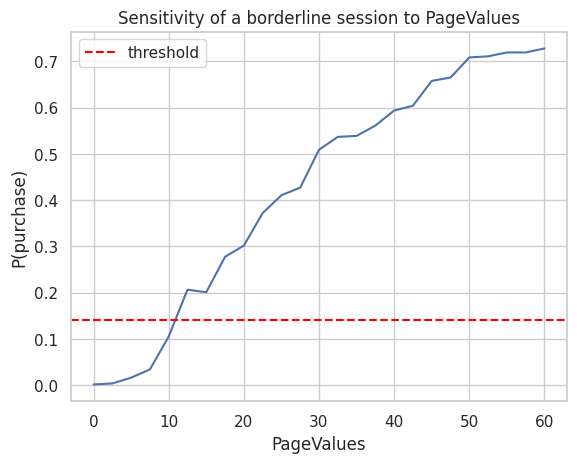

In [6]:
base = pd.DataFrame([ex['borderline']['input']])[S.input_columns]
vals = np.linspace(0, 60, 25)
probs = []
for v in vals:
    r = base.copy(); r['PageValues'] = v
    probs.append(pred.pipeline.predict_proba(r)[0, 1])
plt.plot(vals, probs); plt.axhline(pred.threshold, color='red', ls='--', label='threshold'); plt.xlabel('PageValues'); plt.ylabel('P(purchase)'); plt.legend(); plt.title('Sensitivity of a borderline session to PageValues'); plt.show()

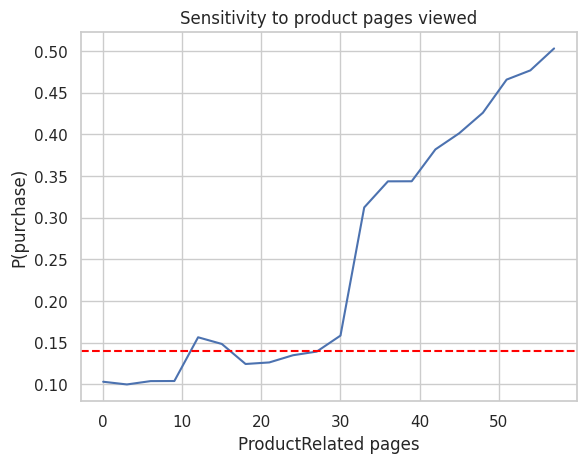

In [7]:
base = pd.DataFrame([ex['borderline']['input']])[S.input_columns]
vals = np.arange(0, 60, 3)
probs = []
for v in vals:
    r = base.copy(); r['ProductRelated'] = v
    probs.append(pred.pipeline.predict_proba(r)[0, 1])
plt.plot(vals, probs); plt.axhline(pred.threshold, color='red', ls='--'); plt.xlabel('ProductRelated pages'); plt.ylabel('P(purchase)'); plt.title('Sensitivity to product pages viewed'); plt.show()

## Takeaways
1. The model relies mostly on `PageValues`, exit/bounce behaviour and product-page engagement - plausible, explainable drivers.
2. SHAP and LIME agree on the dominant driver (`PageValues`); beyond that, trust SHAP.
3. For business use, remember the late-session nature of `PageValues` (see notebook 03).
4. Explanations describe the **model's behaviour**, not causal effects: nudging a visitor to view more pages is not guaranteed to cause a purchase.